In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

import sys
sys.path.append('./helpers')

from customSINDy import make_crucifix_forcing, customMIOSR, plot_cv_column, build_theta_SM90, build_theta_crucifix, print_model, summary, all_subsets_R2, plot_rank_dR2

In [3]:
'''
Make interpolated Crucifix forcing and pp12 transformations 
'''
forc_df = pd.read_csv('./forcing/palinsol_ber90_raw.csv')
a_tr=1.06587 #PP12 truncation parameter
forc = make_crucifix_forcing(forc_df, a_tr)


''' 
Load GP mean for spaghetti and standardisation baseline
- slice time
- reverse column order: PAST --> PRESENT
- flip GP derivative sign
- standardise states and derivatives by the GP mean standard deviation and mean
'''
T_KEEP = 800  

GP_mean_raw = pd.read_csv('./observations/GPR_full_traj_dot_l1_1450.csv').iloc[:T_KEEP]

std = lambda a: (a - a.mean()) / a.std()
def prep_mean(col, dcol):
    y = GP_mean_raw[col].values[::-1]
    return std(y), -10 * GP_mean_raw[dcol].values[::-1] / y.std()          

X_mean, dX_mean = prep_mean('dO18_LR04[pm]', 'dO18_LR04_dot[pm/kaBP]')
Y_mean, dY_mean = prep_mean('CO2_Yamamoto[pm]', 'CO2_Yamamoto_dot[pm/kaBP]')
Z_mean, dZ_mean = prep_mean('MgCa_Eld[mmol/mol]', 'MgCa_Eld_dot[mmol/mol/kaBP]')


''' 
Load MC trajectories
'''
X_raw = pd.read_csv('./observations/gp_draws_dO18_LR04_x_1450.csv').iloc[:T_KEEP]
dX_raw = pd.read_csv('./observations/gp_draws_dO18_LR04_xdot_1450.csv').iloc[:T_KEEP]
Y_raw = pd.read_csv('./observations/gp_draws_co2_yamamoto_x_1450.csv').iloc[:T_KEEP]
dY_raw = pd.read_csv('./observations/gp_draws_co2_yamamoto_xdot_1450.csv').iloc[:T_KEEP]
Z_raw = pd.read_csv('./observations/gp_draws_mgca_x_1450.csv').iloc[:T_KEEP]
dZ_raw = pd.read_csv('./observations/gp_draws_mgca_xdot_1450.csv').iloc[:T_KEEP]
Time = -X_raw['age_ka'].values[::-1] 

std_MC = lambda a, col: (a - GP_mean_raw[col].values.mean(axis=0)) / GP_mean_raw[col].values.std(axis=0)
def prep_MC(state, dot, col):
    y = state.drop(columns='age_ka').values[::-1]
    return std_MC(y, col), -10 * dot.drop(columns='age_ka').values[::-1] / GP_mean_raw[col].values.std(axis=0)

X, dX = prep_MC(X_raw, dX_raw, 'dO18_LR04[pm]') 
Y, dY = prep_MC(Y_raw, dY_raw, 'CO2_Yamamoto[pm]') 
Z, dZ = prep_MC(Z_raw, dZ_raw, 'MgCa_Eld[mmol/mol]')



In [4]:
''' 
GP mean CustomMIOSR SINDy fit
'''

Esi, Eco, O = (std(forc[k](Time)) for k in ('Esi', 'Eco', 'O'))
Theta_X, _ = build_theta_crucifix(X_mean, Y_mean, Z_mean, Esi, Eco, O, max_forcing_degree=1, max_forcing_term_degree=1)
Theta_YZ, _ = build_theta_SM90(X_mean, Y_mean, Z_mean)

alphas = [0, 0, 0]
sparsity_range_X = (1, 32)
sparsity_range_YZ = (1, 20)
timeout = 100
print('X')
Xmodels, XMMSEs, XR2s, Xdfs, optimal = customMIOSR(dX_mean, Theta_X, sparsity_range_X, n_blocks=6, normalize=True, alpha=alphas[0], timeout=timeout)
print('Y')
Ymodels, YMMSEs, YR2s, Ydfs, optimal = customMIOSR(dY_mean, Theta_YZ, sparsity_range_YZ, n_blocks=6, normalize=True, alpha=alphas[1], timeout=timeout)
print('Z')
Zmodels, ZMMSEs, ZR2s, Zdfs, optimal = customMIOSR(dZ_mean, Theta_YZ, sparsity_range_YZ, n_blocks=6, normalize=True, alpha=alphas[2], timeout=timeout)

X
Set parameter Username
Set parameter LicenseID to value 2880530
Academic license - for non-commercial use only - expires 2027-11-02
Y
Z


X (k=4): best = X + Z + Esi + O   R2 = 0.5063
 rank       R2      dR2               terms
    1 0.506308 0.000000     X + Z + Esi + O
    2 0.492163 0.014145 Z + Esi + O + X*X*X
    3 0.489443 0.016865     Y + Z + Esi + O
    4 0.487886 0.018421 Z + Esi + O + X*X*Y
    5 0.484201 0.022106 Z + Esi + O + X*Y*Y 

Y (k=5): best = Z + X*X + X*Y + Z*Z + Y*Y*Z   R2 = 0.2354
 rank       R2      dR2                       terms
    1 0.235369 0.000000 Z + X*X + X*Y + Z*Z + Y*Y*Z
    2 0.227252 0.008117 Z + X*X + X*Y + Z*Z + X*Y*Z
    3 0.224725 0.010644     Y + Z + X*X + X*Y + Z*Z
    4 0.217195 0.018175     Y + Z + X*X + X*Y + Y*Y
    5 0.217123 0.018246 Z + X*X + X*Y + Z*Z + Y*Z*Z 

Z (k=4): best = X + Z + X*Y + Z*Z   R2 = 0.1713
 rank       R2      dR2             terms
    1 0.171313 0.000000 X + Z + X*Y + Z*Z
    2 0.168840 0.002473   1 + X + Z + X*Y
    3 0.165529 0.005783 X + Z + X*X + Z*Z
    4 0.163748 0.007564 X + Z + X*Y + Y*Y
    5 0.160823 0.010489   1 + X + Z + X*X 

X (4 terms) = 

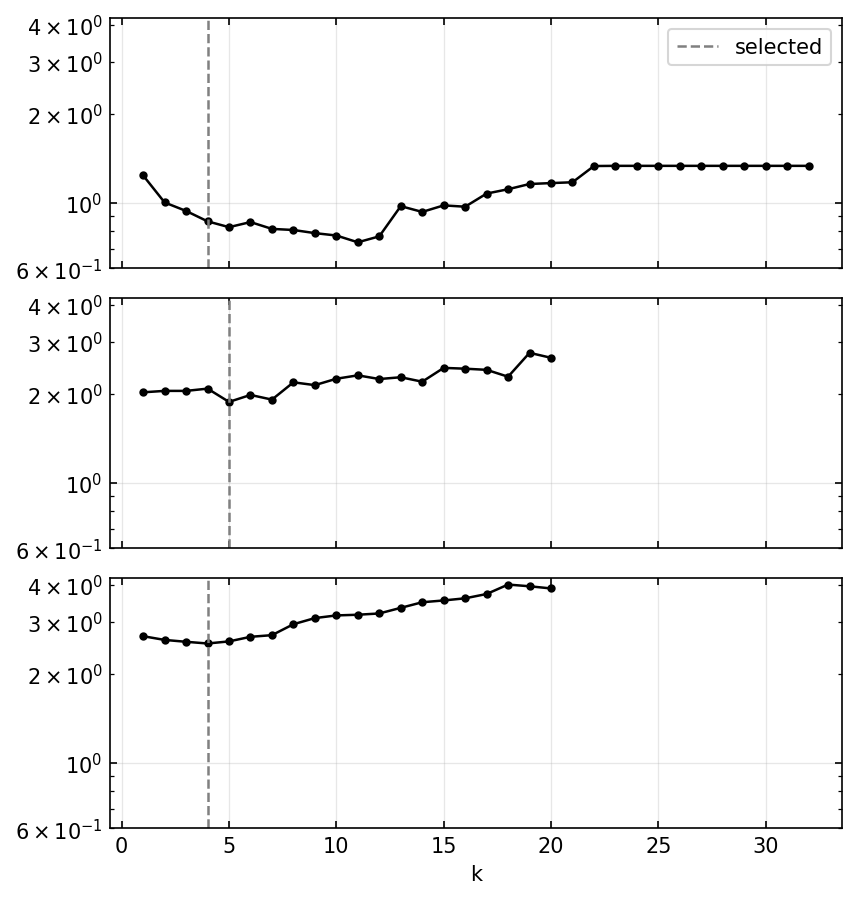

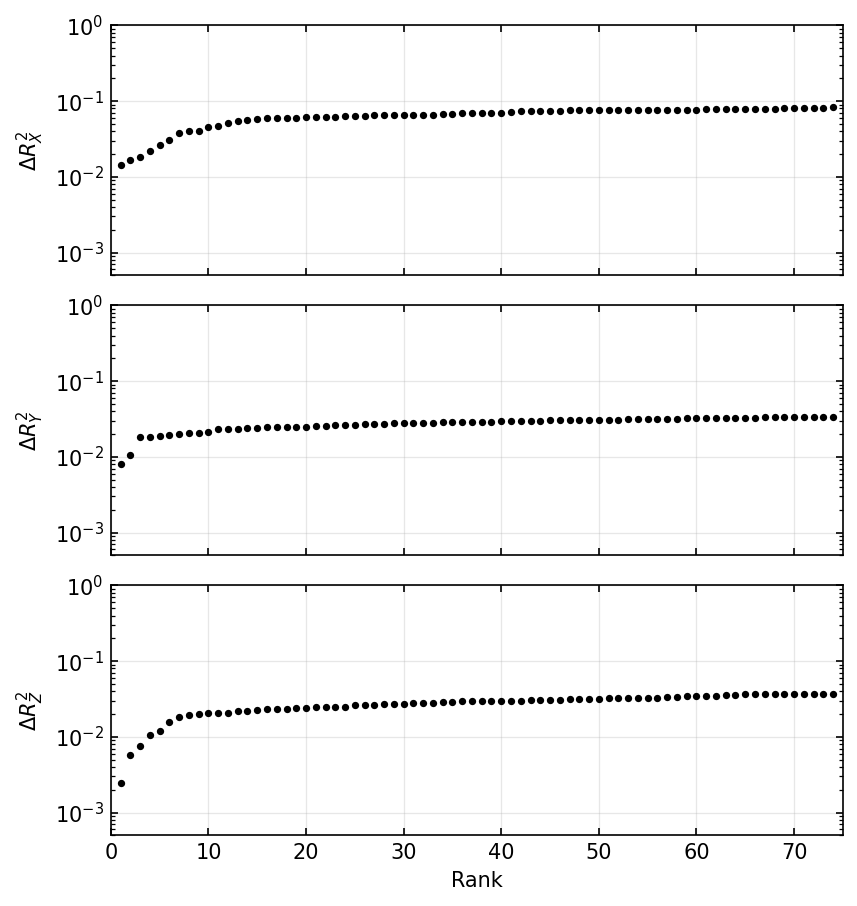

In [5]:
''' 
CV-curve
'''
plot_cv_column([XMMSEs, YMMSEs, ZMMSEs],
               logy=True,
               xlabel='k',
               ylim=(0.6, 4.2),
               best=False,
               sel=[4, 5, 4],
               yticklabels=True,
               legend=True,
               width=6,
               margins=True, save_path='figs_SM90/cv_gp_mean_LP.pdf')

''' 
uniqueness
'''
n_top = 75
dots = {'X': dX_mean, 'Y': dY_mean, 'Z': dZ_mean}
Ks = {'X': 4, 'Y': 5, 'Z':4}
Thetas = {'X': Theta_X, 'Y': Theta_YZ, 'Z': Theta_YZ}
subset_tables = {eq: all_subsets_R2(dots[eq], Thetas[eq], k, n_top=n_top) for eq, k in Ks.items()}

for eq, df in subset_tables.items():
    print(f"{eq} (k={Ks[eq]}): best = {df['terms'].iloc[0]}   R2 = {df['R2'].iloc[0]:.4f}")
    print(df.head(5).to_string(index=False), '\n')

plot_rank_dR2(list(subset_tables.values()),
              y='dR2',
              ylabels=[r'$\Delta R^2_X$', r'$\Delta R^2_Y$', r'$\Delta R^2_Z$'],
              logy=True,
              width=6,
              margins=True, save_path='figs_SM90/LP_rank_dR2.pdf',
              ylim=(5e-4, 1),
              markers=True,
              ms= 2.5,
              drop_best=True)



print_model(Xmodels, 4, 'X')
print(XR2s[4])
print_model(Ymodels, 5, 'Y')
print(YR2s[5])
print_model(Zmodels, 4, 'Z')
print(ZR2s[4])


In [5]:
''' 
MC CustomMIOSR SINDy
'''

import pysindy as ps
from gurobipy import GRB

Ks = {'X': 4, 'Y': 5, 'Z': 4}
models_mean = {'X': Xmodels, 'Y': Ymodels, 'Z': Zmodels}
ref_support = {eq: list(models_mean[eq][k].index) for eq, k in Ks.items()}
models  = {model: {} for model in Ks}   
fixed   = {model: {} for model in Ks}   
optimal = {model: {} for model in Ks}

normalize = True
timeout = 100
alphas_MC = {'X': 0, 'Y': 0, 'Z': 0}
for i in np.arange(X.shape[1]):

    print(f"draw {i}")

    States_i = {'X': X[:,i], 'Y': Y[:,i], 'Z': Z[:,i]}
    dots_i = {'X': dX[:,i], 'Y': dY[:,i], 'Z': dZ[:,i]}
    
    Theta_Xi, _ = build_theta_crucifix(States_i['X'], States_i['Y'], States_i['Z'], Esi, Eco, O, max_forcing_degree=1, max_forcing_term_degree=1)
    A_Xi = Theta_Xi.to_numpy()
    scale_Xi = np.linalg.norm(A_Xi, axis=0) if normalize else np.ones(A_Xi.shape[1])

    Theta_YZi, _ = build_theta_SM90(States_i['X'], States_i['Y'], States_i['Z'])
    A_YZi = Theta_YZi.to_numpy()
    scale_YZi = np.linalg.norm(A_YZi, axis=0) if normalize else np.ones(A_YZi.shape[1])

    Thetas_i = {'X':Theta_Xi, 'Y':Theta_YZi, 'Z':Theta_YZi}
    As_i = {'X':A_Xi, 'Y':A_YZi, 'Z':A_YZi}
    scales_i = {'X':scale_Xi, 'Y':scale_YZi, 'Z':scale_YZi}

    for model, k in Ks.items():

        
        y = dots_i[model]
        opt = ps.MIOSR(target_sparsity=k, alpha=alphas_MC[model], regression_timeout=timeout)
        opt.fit(As_i[model] / scales_i[model], y)
        w = pd.Series(opt.coef_[0] / scales_i[model], index=Thetas_i[model].columns)
        optimal[model][i] = opt.model.Status == GRB.OPTIMAL
        models[model][i] = w
        

        S   = ref_support[model]
        idx = Thetas_i[model].columns.get_indexer(S)
        B   = As_i[model][:, idx] / scales_i[model][idx]                     
        c   = np.linalg.solve(B.T @ B + alphas_MC[model] * np.eye(len(S)), B.T @ y)
        fixed[model][i] = pd.Series(c / scales_i[model][idx], index=S)


draw 0
draw 1
draw 2
draw 3
draw 4
draw 5
draw 6
draw 7
draw 8
draw 9
draw 10
draw 11
draw 12
draw 13
draw 14
draw 15
draw 16
draw 17
draw 18
draw 19
draw 20
draw 21
draw 22
draw 23
draw 24
draw 25
draw 26
draw 27
draw 28
draw 29
draw 30
draw 31
draw 32
draw 33
draw 34
draw 35
draw 36
draw 37
draw 38
draw 39
draw 40
draw 41
draw 42
draw 43
draw 44
draw 45
draw 46
draw 47
draw 48
draw 49
draw 50
draw 51
draw 52
draw 53
draw 54
draw 55
draw 56
draw 57
draw 58
draw 59
draw 60
draw 61
draw 62
draw 63
draw 64
draw 65
draw 66
draw 67
draw 68
draw 69
draw 70
draw 71
draw 72
draw 73
draw 74
draw 75
draw 76
draw 77
draw 78
draw 79
draw 80
draw 81
draw 82
draw 83
draw 84
draw 85
draw 86
draw 87
draw 88
draw 89
draw 90
draw 91
draw 92
draw 93
draw 94
draw 95
draw 96
draw 97
draw 98
draw 99
draw 100
draw 101
draw 102
draw 103
draw 104
draw 105
draw 106
draw 107
draw 108
draw 109
draw 110
draw 111
draw 112
draw 113
draw 114
draw 115
draw 116
draw 117
draw 118
draw 119
draw 120
draw 121
draw 122
dra

In [6]:
models_mean_k = {'X': Xmodels[4], 'Y': Ymodels[5], 'Z': Zmodels[4]}
MIORS_dfs = {model: pd.DataFrame(dict).T for model, dict in models.items()}
fixed_dfs = {model: pd.DataFrame(dict).T for model, dict in fixed.items()}
summaries = {}
for model, df in MIORS_dfs.items():

    df['optimal'] = pd.Series(optimal[model])
    print(f"model={model}: {(~df["optimal"]).sum()} fit(s) not proven optimal")
    summaries[model] = summary(fixed_dfs[model], MIORS_dfs[model], models_mean_k[model])

model=X: 0 fit(s) not proven optimal
model=Y: 0 fit(s) not proven optimal
model=Z: 0 fit(s) not proven optimal


In [7]:
summaries['X']

,GP,mu,med,lo,hi,inc,occurrence
X,-0.410868,-0.359726,-0.360178,-0.413196,-0.304793,0.966,0.966
Z,-0.505166,-0.417995,-0.419510,-0.491039,-0.340777,0.985,0.966
Esi,-0.429059,-0.442325,-0.442815,-0.482305,-0.404282,1.000,0.966
O,-0.601805,-0.610804,-0.611091,-0.637364,-0.579909,1.000,0.966


In [8]:
summaries['Y']

,GP,mu,med,lo,hi,inc,occurrence
Z,0.737145,0.628311,0.625057,0.469688,0.784161,0.819,0.264
X*X,0.581522,0.531092,0.529981,0.362523,0.713151,0.943,0.264
X*Y,0.733016,0.659275,0.657779,0.498217,0.845343,0.943,0.264
Z*Z,0.236536,0.171764,0.172342,0.080403,0.260800,0.554,0.264
Y*Y*Z,-0.236043,-0.176459,-0.175801,-0.266602,-0.098199,0.350,0.264


In [9]:
summaries['Z']

,GP,mu,med,lo,hi,inc,occurrence
X,0.737760,0.693264,0.691367,0.573111,0.819877,0.867,0.279
Z,0.467335,0.403362,0.403365,0.325174,0.492023,0.900,0.279
X*Y,0.334866,0.315648,0.312571,0.198297,0.441602,0.788,0.279
Z*Z,0.190170,0.158113,0.157365,0.098224,0.221701,0.487,0.279


(<Figure size 2100x900 with 3 Axes>,
 array([<Axes: ylabel='$\\dot{X}$'>, <Axes: ylabel='$\\dot{Y}$'>,
        <Axes: xlabel='Age [ka BP]', ylabel='$\\dot{Z}$'>], dtype=object))

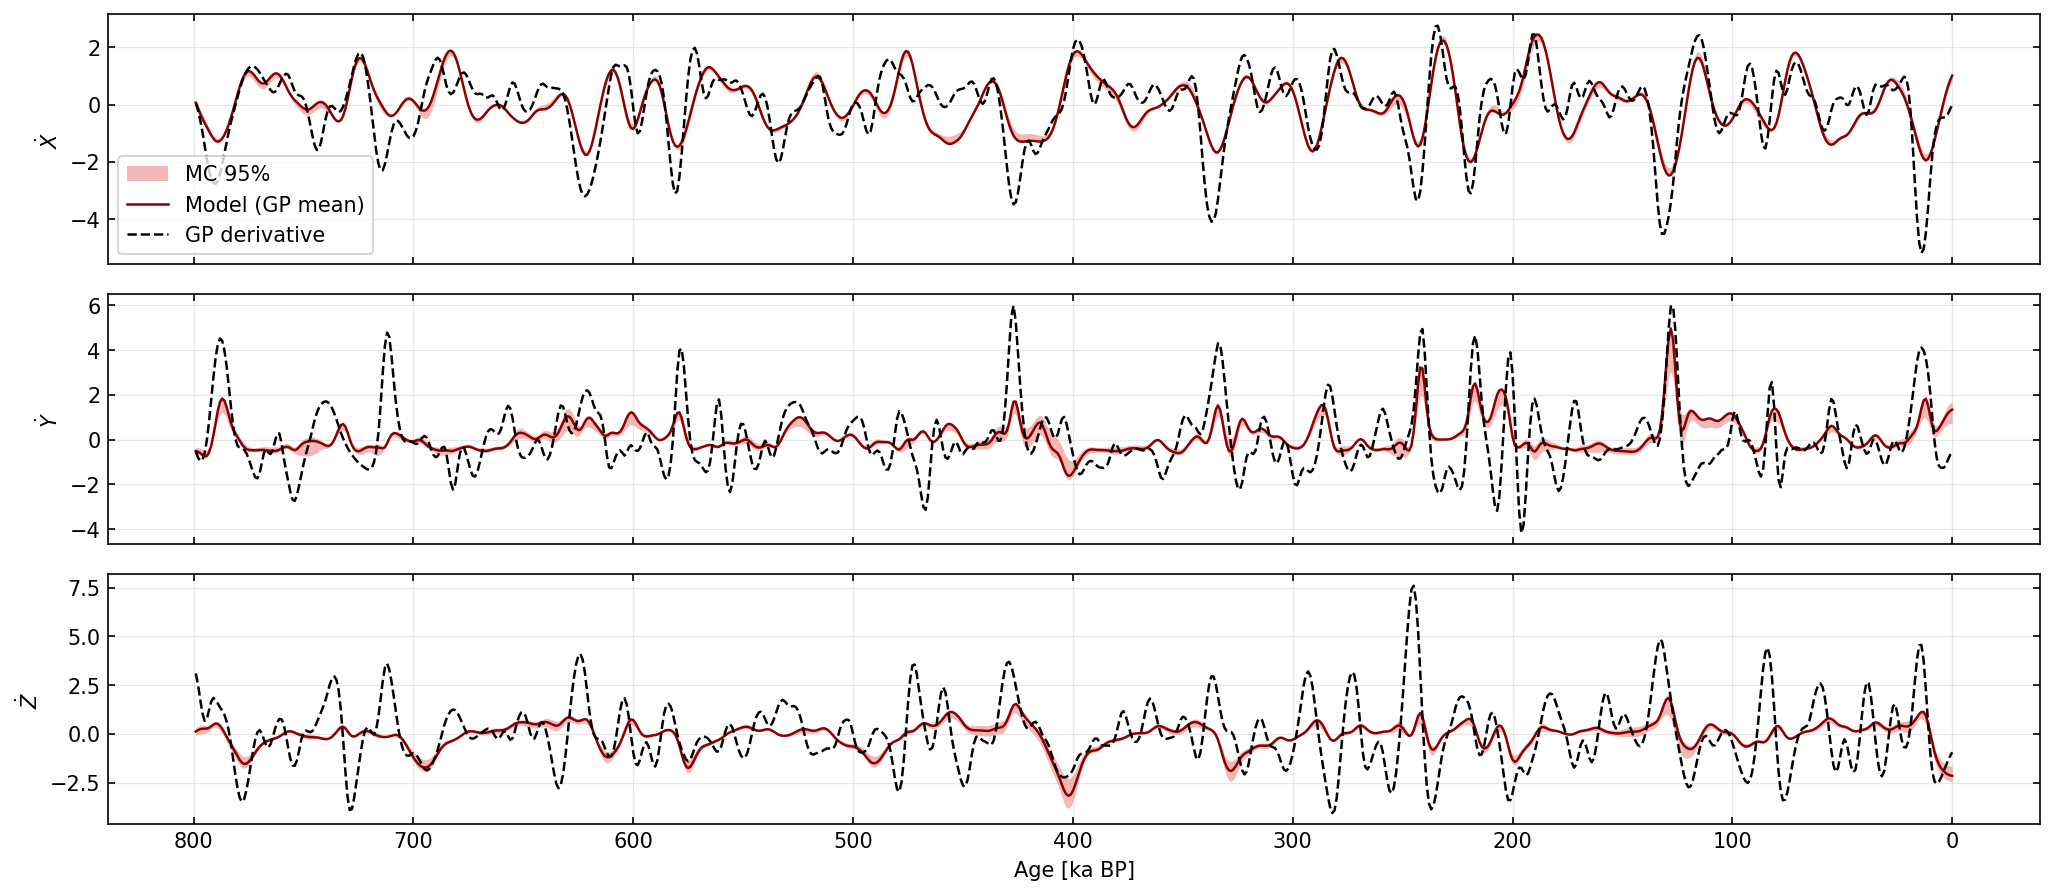

In [10]:
''' 
Derivative time series: GP derivatives vs identified models
- model line: GP-mean coefficients (k from Ks) on the GP-mean library
- band: 2.5-97.5 percentiles of the MC (fixed-support) coefficients on the same library
'''
from tools import plot_timeseries
from GPR import GP_COLOR, GP_BAND

dots_mean = {'X': dX_mean, 'Y': dY_mean, 'Z': dZ_mean}

preds, bands = [], []
for eq, k in Ks.items():
    ref = models_mean[eq][k]
    preds.append(Thetas[eq][ref.index].to_numpy() @ ref.to_numpy())

    W = fixed_dfs[eq][ref.index].to_numpy()                   # (n_draws, k)
    draws = Thetas[eq][ref.index].to_numpy() @ W.T              # (T, n_draws)
    bands.append(np.percentile(draws, [2.5, 97.5], axis=1))

''' 
Slice time window
'''
age = -Time

plot_timeseries(age,
                [p for p in preds],
                ys_true=[dots_mean[eq] for eq in Ks],
                bands=[(lo, hi) for lo, hi in bands],
                band_color=GP_BAND,
                colors=[GP_COLOR], true_color='black',
                labels=[r'$\dot{X}$', r'$\dot{Y}$', r'$\dot{Z}$'],
                legends=['Model (GP mean)', 'GP derivative', 'MC 95%'],
                width=14,
                invert_xaxis=True,
                margins=True, save_path='figs_SM90/ts_derivatives_LP.pdf')


{'X': 697, 'Y': 697, 'Z': 697} NaN points (blow-up)


(<Figure size 900x900 with 3 Axes>,
 array([<Axes: ylabel='X'>, <Axes: ylabel='Y'>,
        <Axes: xlabel='Age [ka BP]', ylabel='Z'>], dtype=object))

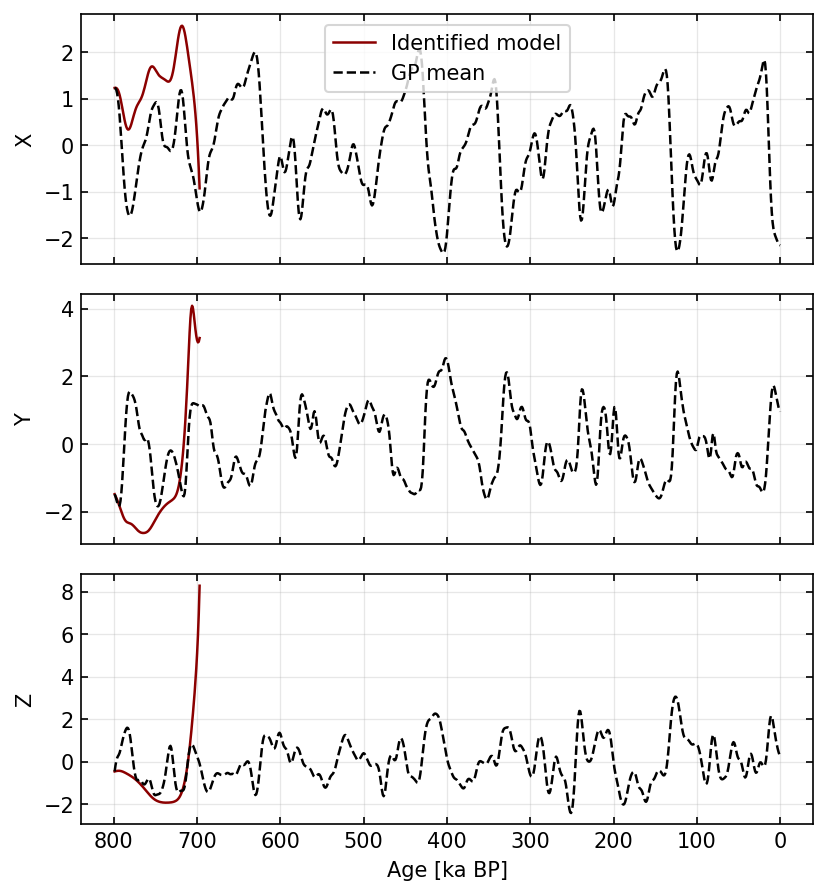

In [11]:
''' 
Integrate the identified GP-mean system (X, Y, Z coupled, forcing interpolated)
- model time unit = 10 kyr (derivatives were scaled by 10), so integrate on Time/10
- initial condition: GP-mean states at the oldest point
'''
from customSINDy import integrate_system

base = pd.DataFrame({'X': X_mean, 'Y': Y_mean, 'Z': Z_mean, 'Esi': Esi, 'Eco': Eco, 'O': O})
ws = {eq: models_mean[eq][k] for eq, k in Ks.items()}
sim = integrate_system(ws, base, Time / 10)
print({eq: int(np.isnan(v).sum()) for eq, v in sim.items()}, 'NaN points (blow-up)')

states_mean = {'X': X_mean, 'Y': Y_mean, 'Z': Z_mean}
plot_timeseries(age,
                [sim[eq] for eq in Ks],
                ys_true=[states_mean[eq] for eq in Ks],
                colors=[GP_COLOR], true_color='black',
                labels=['X', 'Y', 'Z'],
                legends=['Identified model', 'GP mean'],
                width=6,
                invert_xaxis=True,
                margins=True, save_path='figs_SM90/ts_integrated_LP.pdf')


(<Figure size 750x1350 with 3 Axes>,
 array([<Axes: ylabel='X'>, <Axes: ylabel='Y'>, <Axes: ylabel='Z'>],
       dtype=object))

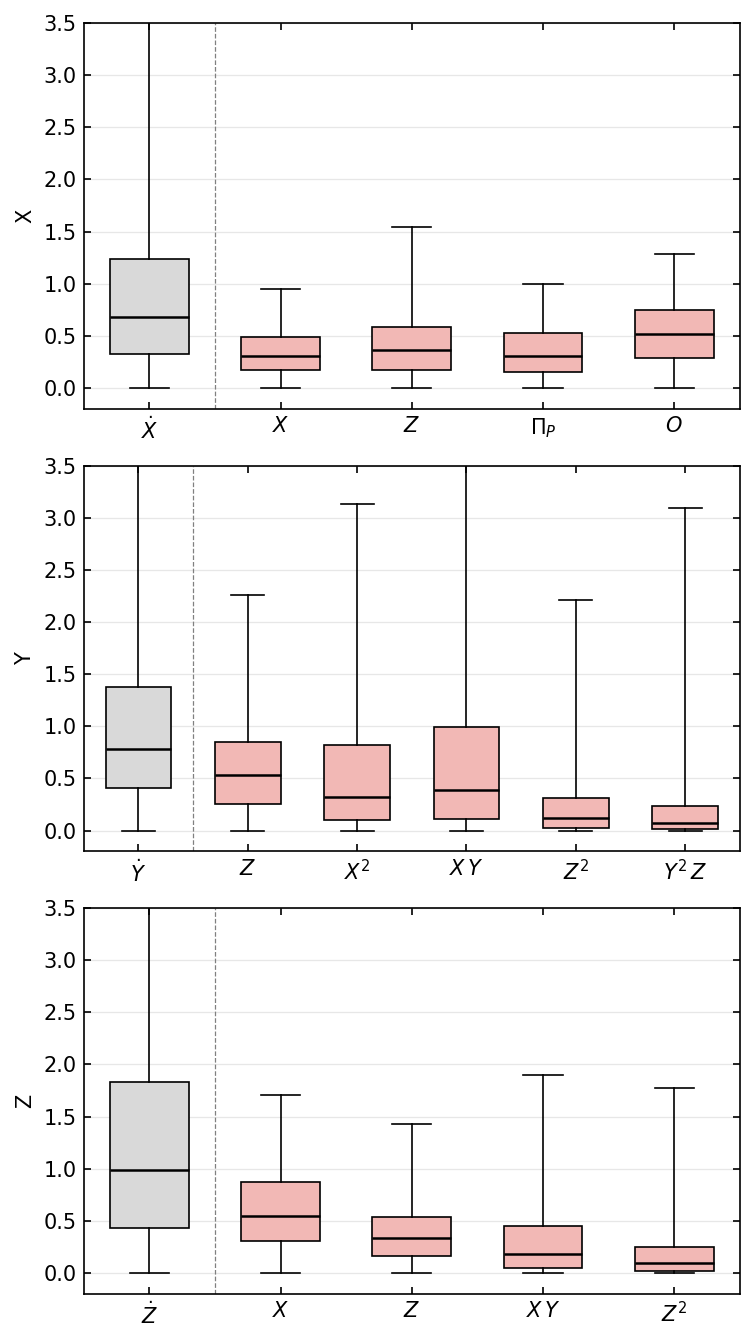

In [12]:
from tools import plot_term_contributions

plot_term_contributions(models_mean_k, Thetas,
                        dots={'X': dX_mean, 'Y': dY_mean, 'Z': dZ_mean},
                        names={'Esi': r'\Pi_P', 'Eco': r'\Pi_c'},
                        absolute=True,
                        ylim = (-0.2, 3.5),
                        ylabels=['X', 'Y', 'Z'],
                        width=5,
                        figsize_per_panel=3,
                        #row=True, width=12,
                        #margins=dict(left=0.07, right=0.99, bottom=0.14, top=0.97, wspace=0.2),
                        save_path='figs_SM90/term_contributions_LP.pdf')


In [13]:
''' 
SM90 reference R^2 on this section of the records
- SM90 forcing R: Q65N (lambda = 120) insolation from the same Berger file, standardised over the fit window
- fixed: SM90's own coefficients on the standardised GP-mean states and derivatives
- refit: least-squares coefficients on SM90's terms (same structure, fitted to the data)
'''
age_f = forc_df['age_kyr'].values[::-1]                                   # ascending age for np.interp
R_sm = std(np.interp(-Time, age_f, forc_df['Q65N_lam120_raw'].values[::-1]))
vars_sm = {'X': X_mean, 'Y': Y_mean, 'Z': Z_mean, 'R': R_sm}
dots_sm = {'X': dX_mean, 'Y': dY_mean, 'Z': dZ_mean}

SM90 = {'X': {'X': -1.0, 'Y': -1.0, 'Z': -0.2, 'R': -0.6},
        'Y': {'Z': -1.0, 'Y': 0.9, 'Z*Z': 1.0, 'Y*Z': -0.5, 'Y*Z*Z': -1.0},
        'Z': {'X': -2.5, 'Z': -2.5}}

term = lambda t: np.prod([vars_sm[f] for f in t.split('*')], axis=0)
r2 = lambda y, pred: 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)

for eq, coefs in SM90.items():
    A = np.column_stack([term(t) for t in coefs])
    y = dots_sm[eq]
    c_fit = np.linalg.lstsq(A, y, rcond=None)[0]
    print(f"{eq}:  R2 fixed = {r2(y, A @ np.array(list(coefs.values()))):8.4f}   "
          f"R2 refit = {r2(y, A @ c_fit):.4f}   refit coefs = "
          + ', '.join(f'{t} {c:.3f}' for t, c in zip(coefs, c_fit)))


X:  R2 fixed =   0.0169   R2 refit = 0.3241   refit coefs = X -0.214, Y 0.232, Z -0.561, R -0.426
Y:  R2 fixed =  -3.0173   R2 refit = 0.1814   refit coefs = Z 0.670, Y -0.238, Z*Z 0.271, Y*Z -0.166, Y*Z*Z -0.089
Z:  R2 fixed =  -2.5838   R2 refit = 0.1188   refit coefs = X 0.726, Z 0.430
